# Business Understanding

## 1. Business Problem: Why is customer churn a problem for a company?

Customer churn occurs when customers stop using a company's products or services. It is a major business problem because losing customers can reduce revenue, increase customer acquisition costs, and negatively affect long-term business growth. Acquiring new customers often requires additional marketing and promotional expenses. Therefore, understanding customer churn can help a company improve customer retention, maintain stable revenue, and build long-term customer relationships.

## 2. Business Objective: How should this analysis help the company?

The primary objective of this analysis is to identify customer characteristics and service-related factors associated with customer churn. By analyzing customer demographics, subscribed services, contract types, tenure, and billing information, we aim to discover patterns that distinguish customers who leave from those who remain.

The findings can help the company identify customer segments with higher churn rates, understand potential areas of dissatisfaction, and develop data-driven customer retention strategies. These insights can also support the development of a machine learning model to estimate the likelihood of customer churn.

## 3. Target Variable: What does the `Churn` column represent?

The `Churn` column indicates whether a customer has left the company's services. It is the target variable for our analysis and potential machine learning classification model.

- **Yes:** The customer has churned.
- **No:** The customer has not churned.

Since the target variable contains two possible outcomes, it represents a binary classification problem. We can analyze the distribution of this variable to understand the overall churn rate and use it as the prediction target when developing a machine learning model.

## 4. Potential Factors: Which customer-related factors might be associated with churn?

Several customer characteristics and service-related factors may be associated with customer churn:

- **Tenure:** Customers with shorter relationships with the company may have different churn patterns from long-term customers.
- **Contract Type:** Customers using month-to-month contracts may exhibit different churn rates compared with customers using one-year or two-year contracts.
- **Monthly Charges:** Higher monthly charges may be associated with different churn patterns.
- **Internet Service:** Churn rates may vary across different internet service types.
- **Payment Method:** Different payment methods may be associated with different customer retention

## 2. Initial Data Audit

The purpose of this stage is to understand the structure, size, and characteristics of the raw dataset before performing any data cleaning or exploratory analysis.

We will examine the number of records and features, column data types, memory usage, and sample observations. This initial audit will help us identify potential data quality issues and plan the next steps of the analysis.

At this stage, we will only inspect the data without modifying or removing any records.

In [3]:
import numpy as n
import pandas as p
import matplotlib.pyplot as plt
import seaborn as s
import warnings
import scipy.stats as stats
warnings.filterwarnings("ignore")

In [4]:
data_set = p.read_csv(r"C:\Users\Pushpraj Pardeshi\Downloads\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [9]:
#shape of the data rows and columns
data_set.shape

(7043, 21)

In [10]:
#name of the fetures in data_set
data_set.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [11]:
#info about data_set (data-types,null-values,shape,etc)
data_set.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [12]:
#top 5 random rows to identify the nature of the data_set
data_set.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
50,8012-SOUDQ,Female,1,No,No,43,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Electronic check,90.25,3838.75,No
3978,0432-CAJZV,Male,0,No,No,3,Yes,No,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,No,Mailed check,90.70,237.65,No
6749,8469-SNFFH,Male,0,Yes,No,70,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,No,One year,No,Bank transfer (automatic),79.40,5528.9,No
2372,0730-BGQGF,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),90.30,6287.3,No
6674,6258-NGCNG,Male,0,No,No,7,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,23.50,173,No


## 3. Data Quality Assessment

Data quality assessment helps determine whether the dataset is complete, consistent, and suitable for further analysis.

In this stage, we will investigate missing values, duplicate records, inconsistent data types, and potential data quality issues. The results will help us decide which cleaning operations are necessary before performing exploratory data analysis.

No records or values will be modified during this assessment.

In [14]:
#here we are going to see missing values in every feture
data_set.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [16]:
#here we are going to see duplicates values in every feture
data_set.duplicated().sum()

np.int64(0)

In [17]:
#data-types of feture for understand proper format
data_set.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [26]:
#number of churn coustomers 
total_customers = len(data_set)

churned_customers = (
    data_set["Churn"] == "Yes"
).sum()

churn_rate = (
    churned_customers / total_customers
) * 100

print(f"Total customers: {total_customers}")
print(f"Churned customers: {churned_customers}")
print(f"Customer churn rate: {churn_rate:.2f}%")

Total customers: 7043
Churned customers: 1869
Customer churn rate: 26.54%


## 4. Data Quality Investigation

In this stage, we will investigate potential data quality issues identified during the initial audit. We will examine missing values, duplicate records, inconsistent categorical values, and suspicious numerical values.

The objective is to determine whether the dataset requires cleaning and to document the reasoning behind each cleaning decision. All investigations will be performed on the original dataset before making any modifications.

In [27]:
# Count missing values in each column
missing_values = data_set.isnull().sum()

# Display only columns containing missing values
display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
)

Series([], dtype: int64)

In [29]:
#to identify why total charge is object 
print("TotalCharges data type:")
print(data_set["TotalCharges"].dtype)

print("\nBlank or whitespace-only values:")
print(
    data_set["TotalCharges"]
    .astype("string")
    .str.strip()
    .eq("")
    .sum()
)

TotalCharges data type:
object

Blank or whitespace-only values:
11


In [32]:
#better understading for stastical term
display(data_set.describe().T)

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


## 5. Data Cleaning and Validation

Data cleaning prepares the dataset for reliable analysis. Each transformation should be based on an identified data quality issue and should preserve the original raw data.

In this stage, we will standardize the `TotalCharges` column, identify values that cannot be converted to numbers, and validate the results before proceeding with further analysis.

In [34]:
# Create a working copy; preserve the original dataset
clean_data = data_set.copy()

# Convert TotalCharges to numeric
clean_data["TotalCharges"] = p.to_numeric(
    clean_data["TotalCharges"].astype("string").str.strip(),
    errors="coerce"
)

# Validate conversion
print("Original dtype:", data_set["TotalCharges"].dtype)
print("New dtype:", clean_data["TotalCharges"].dtype)

print(
    "Missing TotalCharges after conversion:",
    clean_data["TotalCharges"].isna().sum()
)

display(
    clean_data.loc[
        clean_data["TotalCharges"].isna(),
        ["customerID", "tenure", "TotalCharges"]
    ].head(10)
)

Original dtype: object
New dtype: Float64
Missing TotalCharges after conversion: 11


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,<NA>
753,3115-CZMZD,0,<NA>
936,5709-LVOEQ,0,<NA>
1082,4367-NUYAO,0,<NA>
1340,1371-DWPAZ,0,<NA>
3331,7644-OMVMY,0,<NA>
3826,3213-VVOLG,0,<NA>
4380,2520-SGTTA,0,<NA>
5218,2923-ARZLG,0,<NA>
6670,4075-WKNIU,0,<NA>


## 6. Post-Cleaning Validation

After transforming the `TotalCharges` column, we need to verify that the data types are correct, missing values have been identified, and the dataset structure remains consistent.

This validation step ensures that the cleaning process has not unintentionally changed customer records or introduced unexpected data quality issues.

In [35]:
# 1. Verify dataset dimensions
print("Original shape:", data_set.shape)
print("Working copy shape:", clean_data.shape)

# 2. Verify TotalCharges data type
print("\nTotalCharges dtype:")
print(clean_data["TotalCharges"].dtype)

# 3. Count missing values after conversion
print("\nMissing values after conversion:")
display(
    clean_data.isnull()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

# 4. Verify tenure for missing TotalCharges
print("\nTenure distribution for missing TotalCharges:")
display(
    clean_data.loc[
        clean_data["TotalCharges"].isna(), "tenure"
    ].value_counts(dropna=False)
)

# 5. Verify raw data was not modified
print("\nOriginal TotalCharges dtype:")
print(data_set["TotalCharges"].dtype)

Original shape: (7043, 21)
Working copy shape: (7043, 21)

TotalCharges dtype:
Float64

Missing values after conversion:


TotalCharges    11
dtype: int64


Tenure distribution for missing TotalCharges:


tenure
0    11
Name: count, dtype: int64


Original TotalCharges dtype:
object


### 6.1 Findings and Cleaning Decisions

The `TotalCharges` column was originally stored as an object data type, although it represents numerical values. After converting it to a numeric type, 11 missing values were identified.

All 11 records have a tenure of zero months. This suggests that these customers may be new subscribers who have not yet accumulated recorded total charges.

The dataset dimensions remained unchanged at 7,043 rows and 21 columns. The original raw dataset was preserved, and the transformation was performed on a separate working copy.

**Decision:** The 11 missing values will be retained for now. We will investigate their meaning and determine an appropriate treatment strategy before machine learning. No records will be removed solely because of these missing values.

## 7. Univariate Exploratory Data Analysis

Univariate exploratory data analysis examines individual variables to understand their distributions, central tendencies, variability, and potential anomalies.

This stage will focus on customer churn status, tenure, monthly charges, and total charges. The objective is to establish a baseline understanding of the customer population before investigating relationships between multiple variables.

Each analysis will be guided by a specific question, supported by appropriate statistical summaries or visualizations, and followed by an interpretation of the findings.

Customer count by churn status:


,customer_count
Churn,
No,5174
Yes,1869



Customer percentage by churn status:


,percentage
Churn,
No,73.46
Yes,26.54


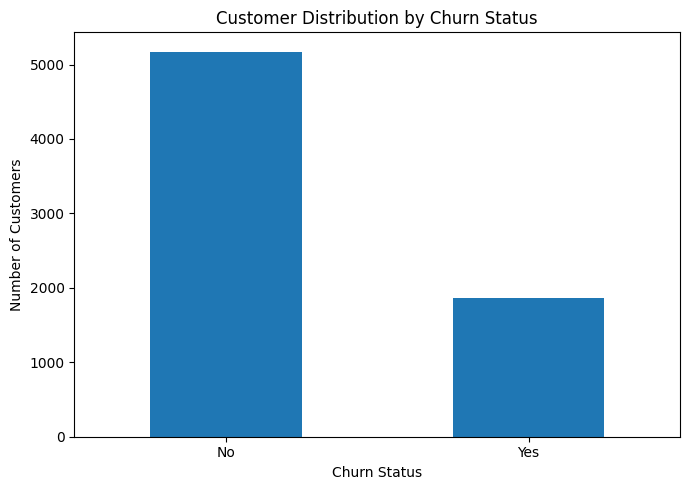

In [36]:
import matplotlib.pyplot as plt

# Customer counts by churn status
churn_counts = clean_data["Churn"].value_counts()

print("Customer count by churn status:")
display(churn_counts.to_frame(name="customer_count"))

print("\nCustomer percentage by churn status:")
display(
    (
        clean_data["Churn"].value_counts(normalize=True) * 100
    ).round(2).to_frame(name="percentage")
)

# Visualize the distribution
ax = churn_counts.plot(
    kind="bar",
    figsize=(7, 5),
    rot=0
)

ax.set_title("Customer Distribution by Churn Status")
ax.set_xlabel("Churn Status")
ax.set_ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### 7.1 Customer Churn Distribution

**Objective:** To understand the distribution of customers across the two churn categories.

**Key Findings:**

- The dataset contains 7,043 customers.
- A total of 5,174 customers (73.46%) did not churn.
- A total of 1,869 customers (26.54%) churned.
- The majority of customers remained with the company, while approximately one in four customers churned.

**Business Interpretation:**

The observed churn rate indicates that customer attrition is an important business concern in this dataset. Understanding the characteristics and behaviours of customers who churn may help the company identify opportunities to improve retention.

**Machine Learning Implications:**

The target variable is moderately imbalanced because the retained-customer class is substantially larger than the churned-customer class. Therefore, accuracy alone may not provide a complete picture of model performance. Precision, recall, F1-score, and the confusion matrix should also be considered during model evaluation.

**Limitation:**

These results describe the distribution of churn in the available dataset. They do not explain why customers leave or establish which factors cause churn. Further exploratory and statistical analyses are required.

In [37]:
# Summary statistics for tenure
display(clean_data["tenure"].describe())

# Additional statistics
print("Median tenure:", clean_data["tenure"].median())
print("Unique tenure values:", clean_data["tenure"].nunique())
print("Zero-tenure customers:", (clean_data["tenure"] == 0).sum())

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

Median tenure: 29.0
Unique tenure values: 73
Zero-tenure customers: 11


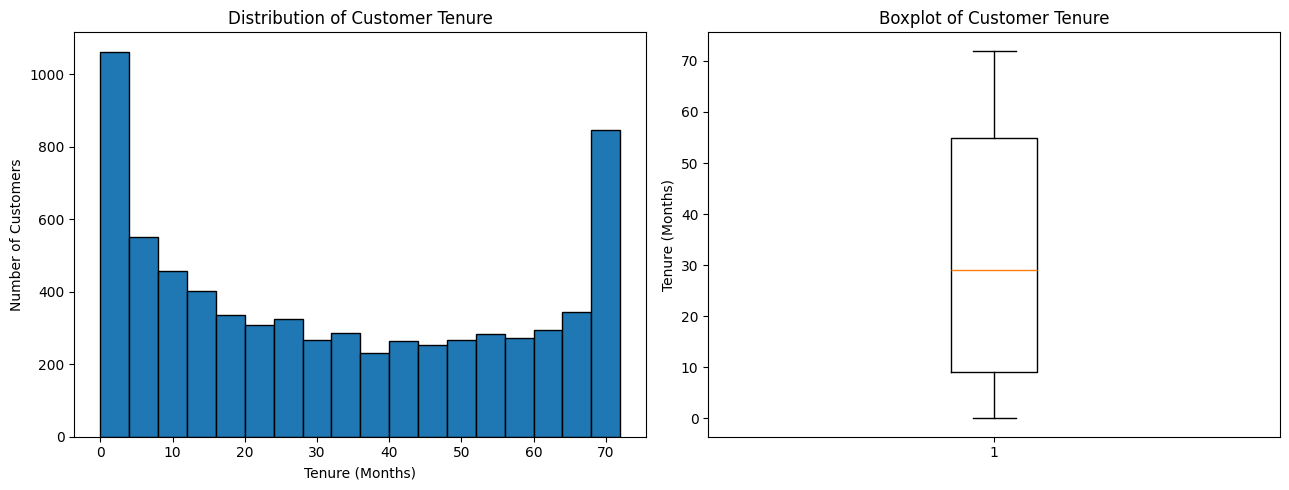

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Histogram: distribution of customer tenure
axes[0].hist(clean_data["tenure"], bins=18, edgecolor="black")
axes[0].set_title("Distribution of Customer Tenure")
axes[0].set_xlabel("Tenure (Months)")
axes[0].set_ylabel("Number of Customers")

# Boxplot: spread and potential outliers
axes[1].boxplot(clean_data["tenure"], vert=True)
axes[1].set_title("Boxplot of Customer Tenure")
axes[1].set_ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

In [39]:
tenure_churn_summary = (
    clean_data.groupby("Churn")["tenure"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(tenure_churn_summary)

,count,mean,median
Churn,,,
No,5174,37.57,38.0
Yes,1869,17.98,10.0


### 7.3 Customer Tenure by Churn Status

**Objective:** To compare the tenure of customers who churned with those who remained with the company.

**Key Findings:**
- The dataset contains 5,174 retained customers and 1,869 churned customers.
- Retained customers have an average tenure of 37.57 months, compared with 17.98 months for churned customers.
- The median tenure is 38 months for retained customers and 10 months for churned customers.
- The substantial difference in median tenure suggests that churned customers tend to leave earlier in their relationship with the company.

**Business Interpretation:**

The findings suggest that early customer retention may be an important area for further investigation. The company could examine the experiences of newer customers and explore whether onboarding, service quality, pricing, or contract conditions are associated with early churn.

**Limitation:**

These descriptive statistics show an association between tenure and churn status. They do not establish that shorter tenure causes churn, and further analysis is needed to investigate other potentially related factors.

**Next Step:** Visualize tenure by churn status to compare the distributions of retained and churned customers.

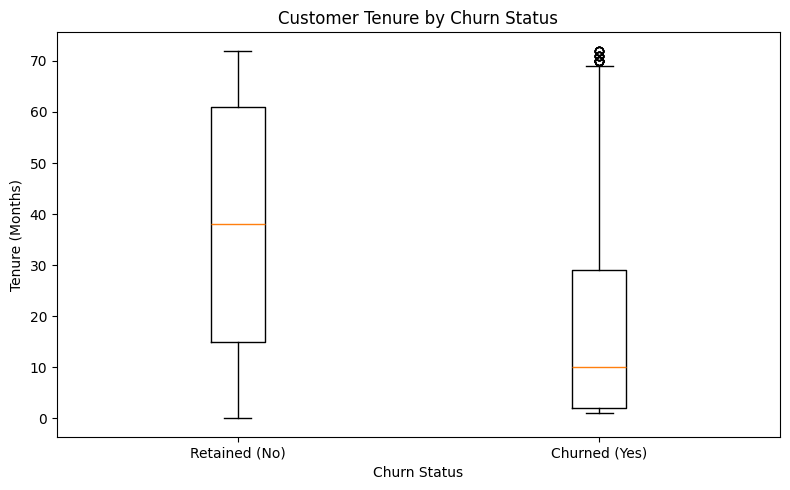

In [40]:
import matplotlib.pyplot as plt

tenure_groups = [
    clean_data.loc[clean_data["Churn"] == "No", "tenure"],
    clean_data.loc[clean_data["Churn"] == "Yes", "tenure"]
]

plt.figure(figsize=(8, 5))
plt.boxplot(tenure_groups, tick_labels=["Retained (No)", "Churned (Yes)"])
plt.title("Customer Tenure by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.tight_layout()
plt.show()

### 7.4 Visual Comparison of Tenure by Churn Status

**Key Findings:**
- Retained customers have a median tenure of 38 months, whereas churned customers have a median tenure of 10 months.
- The tenure distribution of churned customers includes observations at the higher end that appear as potential outliers in the boxplot.
- These observations indicate that some customers churn even after maintaining a relationship with the company for a longer period.

**Business Interpretation:**

The comparison reinforces the importance of investigating early customer churn. However, the presence of long-tenure customers who churn suggests that retention efforts should not focus exclusively on new customers.

**Data Quality Consideration:**

Potential outliers are not automatically errors. These observations should be retained unless further investigation identifies invalid or incorrect records.

count    7043.00
mean       64.76
std        30.09
min        18.25
25%        35.50
50%        70.35
75%        89.85
max       118.75
Name: MonthlyCharges, dtype: float64

Unique monthly charge values: 1585


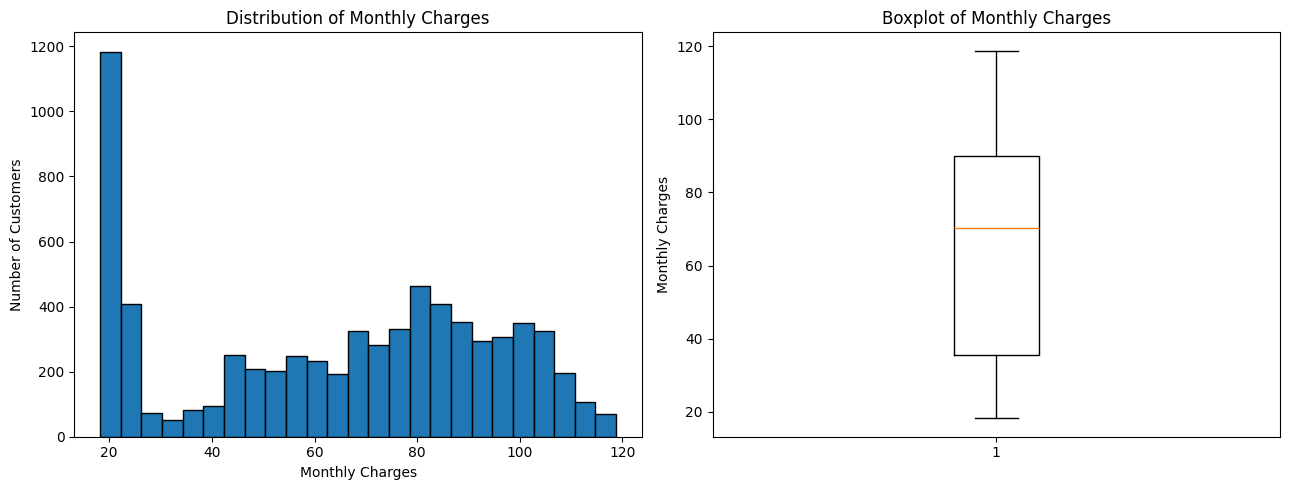

In [41]:
display(clean_data["MonthlyCharges"].describe().round(2))

print(
    "Unique monthly charge values:",
    clean_data["MonthlyCharges"].nunique()
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    clean_data["MonthlyCharges"],
    bins=25,
    edgecolor="black"
)
axes[0].set_title("Distribution of Monthly Charges")
axes[0].set_xlabel("Monthly Charges")
axes[0].set_ylabel("Number of Customers")

axes[1].boxplot(clean_data["MonthlyCharges"])
axes[1].set_title("Boxplot of Monthly Charges")
axes[1].set_ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

### 7.5 Monthly Charges Distribution

**Objective:** To understand the distribution and variability of monthly charges across customers.

**Key Findings:**
- The average monthly charge is 64.76, while the median is 70.35.
- Monthly charges range from 18.25 to 118.75.
- The middle 50% of customers have monthly charges between 35.50 and 89.85.
- The standard deviation is 30.09, indicating noticeable variation in monthly charges.
- The dataset contains 1,585 unique monthly charge values.

**Business Interpretation:**

Customers have different monthly billing levels, which may reflect differences in subscribed services or service packages. Further analysis is needed to determine whether monthly charges are associated with customer churn.

**Limitation:**

This analysis describes monthly charges across all customers. It does not establish whether customers paying higher charges are more likely to churn.

count     7032.0
mean      2283.3
std      2266.77
min         18.8
25%       401.45
50%      1397.48
75%      3794.74
max       8684.8
Name: TotalCharges, dtype: Float64

Unique TotalCharges values: 6530
Missing TotalCharges values: 11


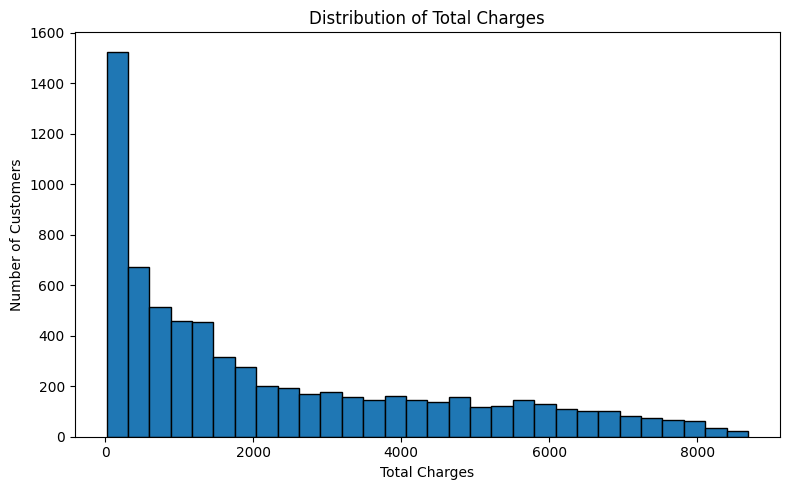

In [42]:
display(clean_data["TotalCharges"].describe().round(2))

print(
    "Unique TotalCharges values:",
    clean_data["TotalCharges"].nunique()
)

print(
    "Missing TotalCharges values:",
    clean_data["TotalCharges"].isna().sum()
)

plt.figure(figsize=(8, 5))
plt.hist(
    clean_data["TotalCharges"].dropna(),
    bins=30,
    edgecolor="black"
)
plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

### 7.6 Total Charges Distribution

**Objective:** To understand the distribution and variability of total charges recorded for customers.

**Key Findings:**
- There are 7,032 non-missing `TotalCharges` records out of 7,043 customers.
- The mean total charge is 2,283.30, while the median is 1,397.48.
- The observed values range from 18.80 to 8,684.80.
- The middle 50% of customers have total charges between 401.45 and 3,794.74.
- The standard deviation is 2,266.77, indicating substantial variability in total charges.
- The mean being higher than the median suggests that the distribution may have a right tail.

**Business Interpretation:**

Total charges can reflect both the amount billed and the length of a customer's relationship with the company. Therefore, this feature should be interpreted alongside tenure and monthly charges rather than in isolation.

**Data Quality Note:**

Eleven records have missing `TotalCharges` values. These records have zero-month tenure, as identified during the earlier data-quality assessment. The missing values have not been automatically replaced or removed.

**Limitation:**

This analysis describes total charges across customers and does not establish a relationship between total charges and churn.

In [43]:
# Compare total charges by churn status
total_charges_summary = (
    clean_data.groupby("Churn")["TotalCharges"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(total_charges_summary)

,count,mean,median
Churn,,,
No,5163,2555.34,1683.6
Yes,1869,1531.8,703.55


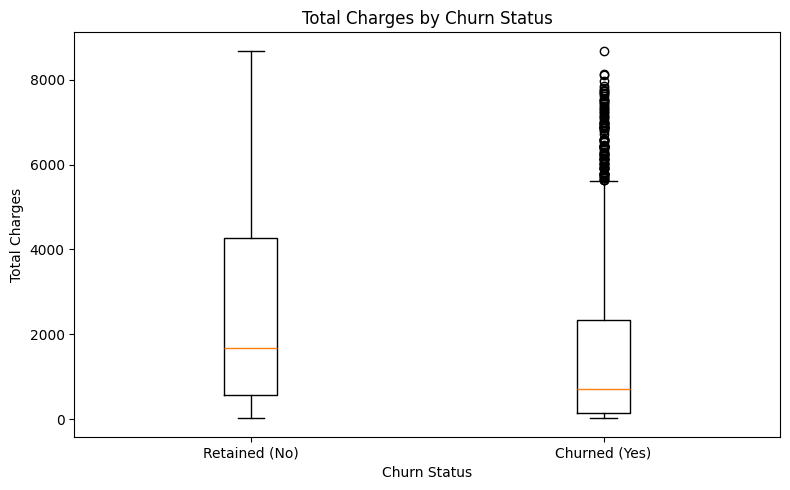

In [44]:
plt.figure(figsize=(8, 5))

total_charges_groups = [
    clean_data.loc[
        clean_data["Churn"] == "No", "TotalCharges"
    ].dropna(),

    clean_data.loc[
        clean_data["Churn"] == "Yes", "TotalCharges"
    ].dropna()
]

plt.boxplot(
    total_charges_groups,
    tick_labels=["Retained (No)", "Churned (Yes)"]
)

plt.title("Total Charges by Churn Status")
plt.xlabel("Churn Status")
plt.ylabel("Total Charges")
plt.tight_layout()
plt.show()

### 7.7 Total Charges by Churn Status

**Key Findings:**
- Retained customers have a mean total charge of 2,555.34 and a median of 1,683.60.
- Churned customers have a mean total charge of 1,531.80 and a median of 703.55.
- Churned customers have lower recorded total charges on both measures.

**Business Interpretation:**

The difference may partly reflect the shorter tenure of churned customers, since customers who leave earlier have less time to accumulate total charges. Therefore, total charges should be interpreted alongside tenure and monthly charges.

**Limitation:**

These results show an association and do not establish that lower total charges cause churn.

In [45]:
contract_summary = clean_data["Contract"].value_counts()

display(
    contract_summary.to_frame(name="customer_count")
)

display(
    (
        clean_data["Contract"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .to_frame(name="percentage")
    )
)

,customer_count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


,percentage
Contract,
Month-to-month,55.02
Two year,24.07
One year,20.91


### 7.8 Contract Type Distribution

**Objective:** To understand how customers are distributed across different contract types.

**Key Findings:**
- Month-to-month contracts represent 55.02% of all customers.
- Two-year contracts account for 24.07% of customers.
- One-year contracts account for 20.91% of customers.
- Month-to-month contracts are the most common contract type in the dataset.

**Business Interpretation:**

More than half of the customers use month-to-month contracts. This makes contract type an important feature to investigate when studying customer retention. However, the distribution alone does not establish whether month-to-month customers have a higher churn rate.

**Next Step:** Compare churn rates across contract types to identify which contract group has the highest observed churn rate.

In [47]:
contract_churn = p.crosstab(
    clean_data["Contract"],
    clean_data["Churn"]
)

contract_churn["Total"] = contract_churn.sum(axis=1)

contract_churn["Churn_Rate_%"] = (
    contract_churn["Yes"] / contract_churn["Total"] * 100
).round(2)

display(contract_churn.sort_values("Churn_Rate_%", ascending=False))

Churn,No,Yes,Total,Churn_Rate_%
Contract,,,,
Month-to-month,2220,1655,3875,42.71
One year,1307,166,1473,11.27
Two year,1647,48,1695,2.83


### 7.9 Churn Rate by Contract Type

**Objective:** To compare customer churn rates across different contract types.

**Key Findings:**
- Month-to-month customers have a churn rate of 42.71%.
- One-year contract customers have a churn rate of 11.27%.
- Two-year contract customers have a churn rate of 2.83%.
- The month-to-month churn rate is approximately 15 times the two-year contract churn rate.

**Business Interpretation:**

Contract type shows a strong association with customer churn in this dataset. Month-to-month customers represent the highest-priority group for further investigation because their observed churn rate is substantially higher than that of customers with longer-term contracts.

The company could investigate whether flexible contract customers would benefit from suitable long-term plans, improved onboarding, or targeted retention offers.

**Limitation:**

These results show an association and do not establish that longer contracts directly cause lower churn. Other factors, such as tenure, service choices, pricing and customer characteristics, may influence the observed relationship.

**Next Step:** Visual

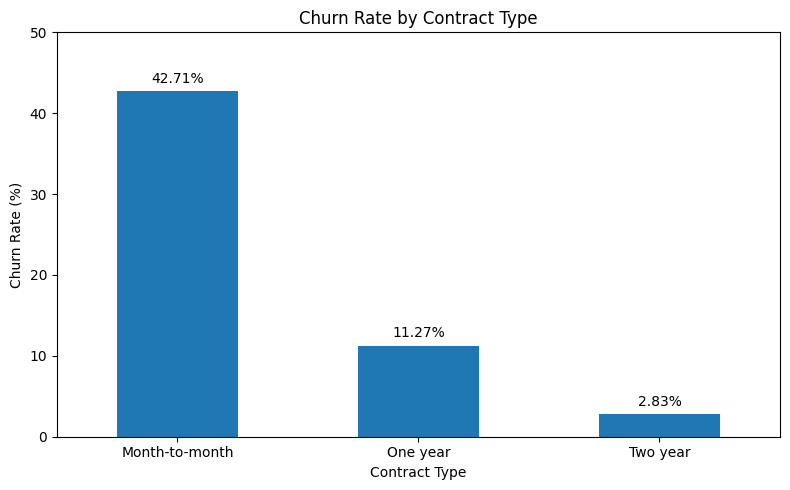

In [50]:
import matplotlib.pyplot as plt

contract_churn_rate = (
    clean_data.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

ax = contract_churn_rate.plot(
    kind="bar",
    figsize=(8, 5),
    rot=0
)

ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Churn Rate (%)")
ax.set_ylim(0, 50)

for i, value in enumerate(contract_churn_rate):
    ax.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()
plt.show()

In [52]:
payment_counts = clean_data["PaymentMethod"].value_counts()

payment_summary = p.DataFrame({
    "customer_count": payment_counts,
    "percentage": (
        clean_data["PaymentMethod"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(payment_summary)

,customer_count,percentage
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61


### 7.10 Payment Method Distribution

**Objective:** To understand the distribution of customers across available payment methods.

**Key Findings:**
- Electronic check is the most common payment method, used by 33.58% of customers.
- Mailed check accounts for 22.89% of customers.
- Automatic bank transfer and automatic credit card payments account for 21.92% and 21.61%, respectively.
- The three remaining payment methods have relatively similar customer shares.

**Business Interpretation:**

Electronic check is the largest payment-method segment in the dataset. Comparing churn rates across payment methods may help identify customer groups that deserve further investigation.

**Limitation:**

Payment-method distribution alone does not show whether a particular payment method is associated with higher churn. A group-level churn-rate comparison is required before drawing conclusions.

In [55]:
payment_churn = p.crosstab(
    clean_data["PaymentMethod"],
    clean_data["Churn"]
)

payment_churn["Total"] = payment_churn.sum(axis=1)

payment_churn["Churn_Rate_%"] = (
    payment_churn["Yes"]
    / payment_churn["Total"]
    * 100
).round(2)

display(
    payment_churn.sort_values(
        "Churn_Rate_%",
        ascending=False
    )
)

Churn,No,Yes,Total,Churn_Rate_%
PaymentMethod,,,,
Electronic check,1294,1071,2365,45.29
Mailed check,1304,308,1612,19.11
Bank transfer (automatic),1286,258,1544,16.71
Credit card (automatic),1290,232,1522,15.24


### 7.11 Churn Rate by Payment Method

**Objective:** To compare customer churn rates across payment methods.

**Key Findings:**
- Electronic check users have the highest observed churn rate at 45.29%.
- Mailed check users have a churn rate of 19.11%.
- Automatic bank transfer users have a churn rate of 16.71%.
- Automatic credit card users have the lowest observed churn rate at 15.24%.

**Business Interpretation:**

Payment method is a potentially useful feature for further churn analysis. The difference between electronic check users and customers using automatic payment methods warrants further investigation. However, the relationship may be influenced by other factors, such as contract type and tenure.

**Limitation:**

These findings indicate an association, not causation. The company should investigate whether payment method remains associated with churn after accounting for other customer characteristics.

## 8. Exploratory Data Analysis — Summary

### Key Findings

1. **Overall churn:** 1,869 of 7,043 customers churned, representing 26.54% of the dataset.
2. **Tenure:** Churned customers have a median tenure of 10 months, compared with 38 months for retained customers.
3. **Contract type:** Month-to-month customers have a churn rate of 42.71%, compared with 11.27% for one-year contracts and 2.83% for two-year contracts.
4. **Payment method:** Electronic check users have the highest observed churn rate at 45.29%, while automatic credit card users have the lowest at 15.24%.
5. **Total charges:** Churned customers have lower median total charges than retained customers. This may partly reflect their shorter tenure.

### Data Quality Considerations

- `TotalCharges` was converted from text to a numeric data type.
- Eleven missing `TotalCharges` values were identified, all among customers with zero-month tenure.
- The original dataset was preserved, and analysis was performed on a working copy.
- Missing values and potential outliers should be handled based on their meaning and the requirements of the modelling pipeline.

### Limitations

- The observed relationships do not establish causation.
- Customer groups may differ in several characteristics simultaneously.
- The findings describe this dataset and may not generalize to every telecom business or customer population.

### Conclusion

The exploratory analysis identifies tenure, contract type, payment method and total charges as useful candidates for further investigation. The next stage will build and evaluate a classification model to estimate customer churn risk using an appropriate train/test split and suitable evaluation metrics.

In [56]:
print("Dataset shape:", clean_data.shape)

display(
    clean_data.dtypes.to_frame(name="data_type")
)

print("Target distribution:")
display(clean_data["Churn"].value_counts())

Dataset shape: (7043, 21)


,data_type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Target distribution:


Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [57]:
# Separate features and target
X = clean_data.drop(columns=["Churn", "customerID"])
y = clean_data["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class distribution:")
display(y.value_counts().rename(index={0: "No Churn", 1: "Churn"}))

print("\nMissing values in features:")
display(
    X.isnull().sum()
    .loc[lambda s: s > 0]
    .to_frame(name="missing_count")
)

Features shape: (7043, 19)
Target shape: (7043,)

Target class distribution:


Churn
No Churn    5174
Churn       1869
Name: count, dtype: int64


Missing values in features:


,missing_count
TotalCharges,11


In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(
    (y_train.value_counts(normalize=True) * 100).round(2)
)

print("\nTesting target distribution:")
display(
    (y_test.value_counts(normalize=True) * 100).round(2)
)

Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


Testing target distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64

In [59]:
# Numerical columns
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Binary and multi-category columns
categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numerical features:", numeric_features)
print("Number of numerical features:", len(numeric_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

print("\nTotal features identified:",
      len(numeric_features) + len(categorical_features))

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 3

Categorical features: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of categorical features: 16

Total features identified: 19


In [60]:
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [61]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Combine preprocessing and classifier
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train on training data only
baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression model trained successfully.")

Baseline Logistic Regression model trained successfully.


In [64]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Predictions on unseen test data
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
print("Logistic Regression — Test Results")
print("-" * 40)
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Logistic Regression — Test Results
----------------------------------------
Accuracy : 0.8055
Precision: 0.6572
Recall   : 0.5588
F1-score : 0.604
ROC-AUC  : 0.8419

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[926 109]
 [165 209]]


In [63]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [65]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

# XGBoost pipeline
xgb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

# Hyperparameter combinations to explore
param_distributions = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__min_child_weight": [1, 3, 5],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__gamma": [0, 0.1, 0.3],
    "classifier__reg_alpha": [0, 0.1, 1],
    "classifier__reg_lambda": [1, 3, 5, 10]
}

# 5-fold stratified cross-validation
cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="roc_auc",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Train and tune using training data only
random_search.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(random_search.best_score_, 4))
print("\nBest Hyperparameters:")
print(random_search.best_params_)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV ROC-AUC: 0.8504

Best Hyperparameters:
{'classifier__subsample': 0.9, 'classifier__reg_lambda': 1, 'classifier__reg_alpha': 0, 'classifier__n_estimators': 100, 'classifier__min_child_weight': 3, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__gamma': 0, 'classifier__colsample_bytree': 0.8}


In [66]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix
)

best_xgb = random_search.best_estimator_

y_pred_xgb = best_xgb.predict(X_test)
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("Tuned XGBoost — Test Results")
print("-" * 40)
print("Accuracy :", round(accuracy_score(y_test, y_pred_xgb), 4))
print("Precision:", round(precision_score(y_test, y_pred_xgb), 4))
print("Recall   :", round(recall_score(y_test, y_pred_xgb), 4))
print("F1-score :", round(f1_score(y_test, y_pred_xgb), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_xgb), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_xgb,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

Tuned XGBoost — Test Results
----------------------------------------
Accuracy : 0.8091
Precision: 0.6804
Recall   : 0.5294
F1-score : 0.5955
ROC-AUC  : 0.8466

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.88      1035
       Churn       0.68      0.53      0.60       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Confusion Matrix:
[[942  93]
 [176 198]]


In [67]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        min_samples_split=10,
        min_samples_leaf=4,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train only on training data
rf_pipeline.fit(X_train, y_train)

# Test-set predictions
y_pred_rf = rf_pipeline.predict(X_test)
y_prob_rf = rf_pipeline.predict_proba(X_test)[:, 1]

print("Random Forest — Test Results")
print("-" * 40)
print("Accuracy :", round(accuracy_score(y_test, y_pred_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_rf), 4))
print("Recall   :", round(recall_score(y_test, y_pred_rf), 4))
print("F1-score :", round(f1_score(y_test, y_pred_rf), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_rf), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_rf,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest — Test Results
----------------------------------------
Accuracy : 0.7693
Precision: 0.5476
Recall   : 0.754
F1-score : 0.6344
ROC-AUC  : 0.8424

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.77      0.83      1035
       Churn       0.55      0.75      0.63       374

    accuracy                           0.77      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.77      0.78      1409

Confusion Matrix:
[[802 233]
 [ 92 282]]
